In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import month_plot, quarter_plot, plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error
import seaborn as sns

import shap

In [12]:

data_loc = r"~/Desktop/Data Playground/Traffic Flow Forecasting and Analysis"
data_name="traffic_sensor_data.csv"
#df = pd.read_csv(f"{data_loc}/{data_name}") # Linux Option
df = pd.read_csv(f"{data_name}") # Windows Option

## Feature Engineering

In [13]:
def feature_engineering(
    df,
    target_column='vehicle_count',
    lag_steps=(1, 2),
    rolling_window=6,
    keep_timestamp=False,
    drop_na=True,
):
    modern_df = df.copy()
    modern_df['timestamp'] = pd.to_datetime(modern_df['timestamp'])
    modern_df = modern_df.sort_values(['sensor_id', 'timestamp']).reset_index(drop=True)

    # Calendar features are known in advance, so they are valid for forecasting
    modern_df['month'] = modern_df['timestamp'].dt.month
    modern_df['hour'] = modern_df['timestamp'].dt.hour
    modern_df['minute'] = modern_df['timestamp'].dt.minute
    modern_df['day_of_week'] = modern_df['timestamp'].dt.dayofweek
    modern_df['slot_30m'] = modern_df['hour'] * 2 + (modern_df['minute'] // 30)
    modern_df['slot_30m_sin'] = np.sin(2 * np.pi * modern_df['slot_30m'] / 48)
    modern_df['slot_30m_cos'] = np.cos(2 * np.pi * modern_df['slot_30m'] / 48)
    modern_df['day_of_week_sin'] = np.sin(2 * np.pi * modern_df['day_of_week'] / 7)
    modern_df['day_of_week_cos'] = np.cos(2 * np.pi * modern_df['day_of_week'] / 7)
    modern_df['month_sin'] = np.sin(2 * np.pi * (modern_df['month'] - 1) / 12)
    modern_df['month_cos'] = np.cos(2 * np.pi * (modern_df['month'] - 1) / 12)

    # Past-only target history per sensor; shift(1) keeps the current value out of the rolling mean
    grouped_target = modern_df.groupby('sensor_id')[target_column]
    for step in lag_steps:
        modern_df[f'{target_column}_lag_{step}'] = grouped_target.shift(step)
    modern_df[f'{target_column}_roll_mean_{rolling_window}'] = grouped_target.transform(
        lambda s: s.shift(1).rolling(rolling_window, min_periods=rolling_window).mean()
    )

    # Sensor as one integer code; sorted so each sensor keeps the same code in every split
    sensor_codes = {sensor: code for code, sensor in enumerate(sorted(modern_df['sensor_id'].unique()))}
    modern_df['sensor_id'] = modern_df['sensor_id'].map(sensor_codes).astype('int16')

    # Same-slot measurements are unknown at forecast time, and vehicle-type counts sum to the target
    columns_to_drop = [
        'location', 'direction', 'average_speed_kmh', 'occupancy_rate', 'congestion_level',
        'car_count', 'motorcycle_count', 'truck_count', 'bus_count',
        'month', 'hour', 'minute', 'day_of_week', 'slot_30m',
    ]
    if not keep_timestamp:
        columns_to_drop.append('timestamp')
    modern_df = modern_df.drop(columns=columns_to_drop)

    if drop_na:
        history_cols = [
            c for c in modern_df.columns
            if c.startswith(f'{target_column}_lag_') or c.startswith(f'{target_column}_roll_mean_')
        ]
        modern_df = modern_df.dropna(subset=history_cols).reset_index(drop=True)

    return modern_df


def classical_feature_engineering(df, target_column='vehicle_count', **kwargs):
    # Same columns as feature_engineering, indexed by time for the TSFM pipeline
    feats = feature_engineering(df, target_column=target_column, keep_timestamp=True, **kwargs)
    return feats.rename(columns={'timestamp': 'ts'}).set_index('ts')


## Spliting Datasets

In [14]:
# Chronological split on unique timestamps, so each timestamp's sensors stay in the same split
TRAIN_FRACTION = 0.8
VALIDATION_SET = False  # False, or the share of timestamps after train used for validation

def split_dataset(df, classical_full, modern_full, train_fraction=TRAIN_FRACTION, validation_set=VALIDATION_SET):
    timestamps = pd.to_datetime(df['timestamp']).drop_duplicates().sort_values().reset_index(drop=True)
    n = len(timestamps)

    validation_share = 0.0 if validation_set is False else float(validation_set)
    if not 0 <= validation_share <= 1 - train_fraction:
        raise ValueError('validation_set must be False or a share that fits in the remaining timestamps')

    train_end = int(n * train_fraction)
    val_end = train_end + int(n * validation_share)
    train_cut = timestamps.iloc[train_end - 1]
    val_cut = timestamps.iloc[val_end - 1] if val_end > train_end else train_cut

    classical_times = pd.DatetimeIndex(classical_full.index)
    modern_times = pd.DatetimeIndex(modern_full['timestamp'])
    classical_labels = np.select([classical_times <= train_cut, classical_times <= val_cut], ['train', 'validation'], 'test')
    modern_labels = np.select([modern_times <= train_cut, modern_times <= val_cut], ['train', 'validation'], 'test')

    splits = {}
    for name in ['train', 'validation', 'test']:
        splits[name] = {
            'classical': classical_full[classical_labels == name],
            'modern': modern_full[modern_labels == name].reset_index(drop=True),
        }

    print(
        f'Train cutoff: {train_cut} | Validation cutoff: {val_cut} | '
        f"Train timestamps: {(timestamps <= train_cut).sum():,} | "
        f"Validation timestamps: {((timestamps > train_cut) & (timestamps <= val_cut)).sum():,} | "
        f"Test timestamps: {(timestamps > val_cut).sum():,}"
    )
    return splits


# Features are built on the full series first so test rows keep their history from train
classical_full = classical_feature_engineering(df, target_column='vehicle_count')
modern_full = feature_engineering(df, target_column='vehicle_count', keep_timestamp=True)

splits = split_dataset(df, classical_full, modern_full)
classical_train_df = splits['train']['classical']
classical_validation_df = splits['validation']['classical']
classical_test_df = splits['test']['classical']
modern_train_df = splits['train']['modern']
modern_validation_df = splits['validation']['modern']
modern_test_df = splits['test']['modern']

/tmp/ipykernel_10764/1437172770.py:17: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  modern_df['day_of_week'] = modern_df['timestamp'].dt.dayofweek
/tmp/ipykernel_10764/1437172770.py:17: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  modern_df['day_of_week'] = modern_df['timestamp'].dt.dayofweek


Train cutoff: 2024-03-13 18:30:00 | Validation cutoff: 2024-03-13 18:30:00 | Train timestamps: 3,494 | Validation timestamps: 0 | Test timestamps: 874


## Models Loading

#### ML Models

In [5]:
import joblib
import os

model_route = "/home/albertouskas/Desktop/Data Playground/traffic_flow_prediction_forecasting_and_analysis/saved_models"
model_files = sorted(f for f in os.listdir(model_route) if f.endswith(".joblib") and f != "feature_columns.joblib")
models = [joblib.load(f"{model_route}/{f}") for f in model_files]
feature_columns = joblib.load(f"{model_route}/feature_columns.joblib")

In [9]:
models

[HistGradientBoostingRegressor(max_iter=400, random_state=42),
 CatBoostRegressor(depth=8, iterations=400, learning_rate=0.05, loss_function='RMSE', random_seed=42, verbose=False),
 LGBMRegressor(learning_rate=0.05, n_estimators=400, num_leaves=63,
               random_state=42)]

### TFMs Models

In [10]:
import torch
import timesfm
from chronos import Chronos2Pipeline
from uni2ts.model.moirai2 import Moirai2Module
from timestral import TimestralForecaster

USE_CHRONOS2 = True
USE_TIMESFM = True
USE_MOIRAI2 = True
USE_TIMESTRAL = True

model_errors = {}
chronos2_model = timesfm_model = moirai2_module = timestral_model = None

if USE_CHRONOS2:
    try:
        chronos2_model = Chronos2Pipeline.from_pretrained('amazon/chronos-2', device_map='cpu')
    except Exception as exc:
        model_errors['Chronos 2'] = f'{exc.__class__.__name__}: {exc}'

if USE_TIMESFM:
    try:
        timesfm_model = timesfm.TimesFM_2p5_200M_torch.from_pretrained('google/timesfm-2.5-200m-pytorch')
        timesfm_model.model.to('cpu')
        timesfm_model.model.device = torch.device('cpu')
        timesfm_model.model.device_count = 1
        timesfm_model.compile(timesfm.ForecastConfig(
            max_context=2048,
            max_horizon=1024,
            normalize_inputs=True,
            use_continuous_quantile_head=False,
        ))
    except Exception as exc:
        model_errors['TimesFM'] = f'{exc.__class__.__name__}: {exc}'

if USE_MOIRAI2:
    try:
        moirai2_module = Moirai2Module.from_pretrained('Salesforce/moirai-2.0-R-small')
    except Exception as exc:
        model_errors['Moirai 2.0'] = f'{exc.__class__.__name__}: {exc}'

if USE_TIMESTRAL:
    try:
        timestral_model = TimestralForecaster.from_pretrained('mistralai/Timestral-209M', device='cpu')
    except Exception as exc:
        model_errors['Timestral'] = f'{exc.__class__.__name__}: {exc}'

if model_errors:
    display(pd.DataFrame([{'model': k, 'status': v} for k, v in model_errors.items()]))


/home/albertouskas/Desktop/Data Playground/traffic_flow_prediction_forecasting_and_analysis/.venv-tsfm/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Fetching 2 files: 100%|██████████| 2/2 [00:00<00:00, 412.26it/s]


## SHAP Analysis

### ML models

In [16]:
ml_pred = models[0].predict(modern_test_df[feature_columns])

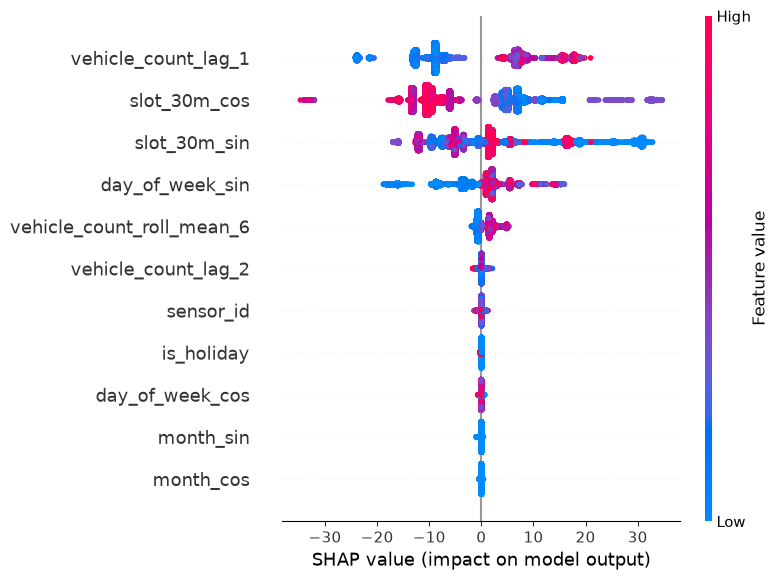

In [19]:
explainer = shap.TreeExplainer(models[0])
shap_values = explainer.shap_values(modern_test_df[feature_columns])
shap.summary_plot(shap_values, modern_test_df[feature_columns])

### TFMs Models

In [ ]:
L = 12
lag_cols = [f'lag_{k}' for k in range(L, 0, -1)]

raw = df[['sensor_id', 'timestamp', 'vehicle_count']].copy()
raw['timestamp'] = pd.to_datetime(raw['timestamp'])
raw = raw.sort_values(['sensor_id', 'timestamp'])
for k in range(1, L + 1):
    raw[f'lag_{k}'] = raw.groupby('sensor_id')['vehicle_count'].shift(k)
raw = raw.dropna(subset=lag_cols)

test_start = pd.DatetimeIndex(classical_test_df.index).min()
X_bg = shap.kmeans(raw.loc[raw['timestamp'] < test_start, lag_cols].sample(2000, random_state=42).to_numpy(float), 10)
X_explain = raw.loc[raw['timestamp'] >= test_start, lag_cols].sample(20, random_state=42).to_numpy(float)


def chronos2_one_step(X):
    quantile_forecasts, _ = chronos2_model.predict_quantiles(
        [np.asarray(row, dtype=np.float32) for row in X],
        prediction_length=1,
        quantile_levels=[0.5],
    )
    return np.array([q[0, 0, 0].detach().cpu().item() for q in quantile_forecasts])


def timesfm_one_step(X):
    point_forecast, _ = timesfm_model.forecast(horizon=1, inputs=[np.asarray(row, dtype=float) for row in X])
    return np.asarray(point_forecast)[:, 0]


def timestral_one_step(X):
    result = timestral_model.forecast(X[:, None, :].astype(float), prediction_length=1)
    return np.asarray(result.median, dtype=float)[:, 0, 0]


tsfm_predictors = {
    'Chronos 2': (chronos2_model, chronos2_one_step),
    #'TimesFM': (timesfm_model, timesfm_one_step),
    #'Timestral': (timestral_model, timestral_one_step),
}

for model_name, (fitted, predict_fn) in tsfm_predictors.items():
    if fitted is None:
        print(f'{model_name}: not loaded, skipped.')
        continue
    explainer = shap.KernelExplainer(predict_fn, X_bg)
    shap_values = explainer.shap_values(X_explain, nsamples=100)
    plt.figure()
    shap.summary_plot(shap_values, X_explain, feature_names=lag_cols, show=False)
    plt.title(f'{model_name} SHAP (one-step forecast)')
    plt.show()


  2%|▏         | 1/50 [02:15<1:50:59, 135.90s/it]